In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

from sklearn.metrics import r2_score

In [ ]:
X = 6 * np.random.rand(40,1) - 3

y = (
    0.6 * X**2
    +0.5 * X
    +5
    + np.random.rand (40,1)
)

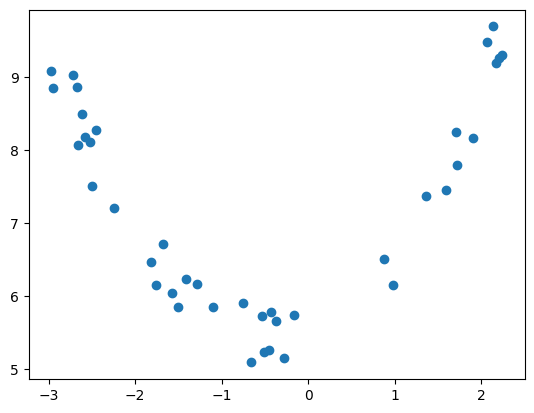

In [ ]:
plt.scatter(X, y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42
)

In [ ]:
poly = PolynomialFeatures(
    degree=15,
    include_bias=False
)

In [ ]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [ ]:
model = LinearRegression()
model.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
train_pred = model.predict(X_train_poly)
test_pred = model.predict(X_test_poly)

In [ ]:
train_pred

array([[7.95961269],
       [6.23892039],
       [5.5083476 ],
       [9.25073209],
       [9.57748724],
       [8.96414299],
       [8.05979959],
       [6.51776547],
       [9.08517067],
       [8.23882177],
       [7.37355937],
       [5.56290166],
       [5.45979129],
       [5.46342899],
       [9.35766176],
       [8.56714217],
       [8.65751217],
       [5.91678812],
       [6.12980795],
       [9.53866065],
       [8.09086598],
       [8.2442888 ],
       [7.97411546],
       [6.16182098]])

In [ ]:
test_pred

array([[9.49076733],
       [6.27224615],
       [7.19474957],
       [9.1399709 ],
       [8.53207945],
       [9.00012222],
       [7.75685893],
       [8.25690365],
       [8.09622389],
       [9.69567108],
       [8.78743552],
       [6.5558992 ],
       [5.72959815],
       [6.94405452],
       [6.34580711],
       [5.66733807]])

In [ ]:
print("Train R_2:", r2_score(y_train, train_pred))
print("Test R_2:", r2_score(y_test, test_pred))

Train R_2: 0.9821657547788913
Test R_2: -0.09696443799350885


In [ ]:
X_new = np.linspace(-3, 3, 200).reshape(-1, 1)

# Convert them to polynomial features
X_new_poly = poly.transform(X_new)

# Let the degree-15 model predict y
y_new = model.predict(X_new_poly)

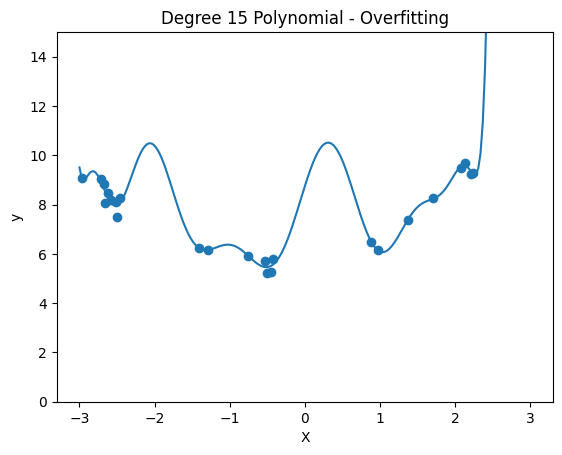

In [ ]:
plt.scatter(X_train, y_train)
plt.plot(X_new, y_new)

plt.ylim(0, 15)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Degree 15 Polynomial - Overfitting")

plt.show()

In [ ]:
scaler = StandardScaler()

In [ ]:
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

In [ ]:
# Ridge regression

ridge = Ridge(alpha=10)
ridge.fit(X_train_scaled, y_train)



Ridge(alpha=10)

In [ ]:
ridge_train_pred = ridge.predict(X_train_scaled)
ridge_test_pred = ridge.predict(X_test_scaled)

In [ ]:
print("Train R2:", r2_score(y_train, ridge_train_pred))
print("Test R2:", r2_score(y_test, ridge_test_pred))

Train R2: 0.856381584216672
Test R2: 0.7893815964895722


In [ ]:
print(ridge.coef_)

[ 0.39220078  0.63805172  0.19122265  0.41286163  0.0965498   0.2559599
  0.04750536  0.14814858  0.0297818   0.07296172  0.03102503  0.01963821
  0.04171961 -0.01885803  0.05583878]


In [ ]:
from sklearn.linear_model import Lasso

In [ ]:
lasso = Lasso(alpha=0.1, max_iter=100000)

In [ ]:
lasso.fit(X_train_scaled, y_train)

lasso_train_pred = lasso.predict(X_train_scaled)
lasso_test_pred = lasso.predict(X_test_scaled)

In [ ]:
print ("Train R²:",r2_score(y_train, lasso_train_pred))
print ("Test R²:",r2_score(y_test, lasso_test_pred))


Train R²: 0.9398684732329496
Test R²: 0.89214786201396


In [ ]:
print(lasso.coef_)

[ 0.67965914  1.42177806  0.          0.          0.          0.
  0.          0.          0.          0.          0.         -0.
  0.         -0.          0.        ]
